# Section 5: Autoencoders and Semi-Supervised Fraud Detection

**What you'll learn**
- Build, compile and train an autoencoder with Keras 3 on PyTorch
- Use its reconstruction error as a fraud score, like PCA in the previous sections
- Change the bottleneck, the depth, the activations and the training length
- Regularise an overcomplete autoencoder with dropout and an L1 penalty
- Train a denoising autoencoder on noisy input
- Combine a few labels with the autoencoder's error
- Spread a few labels with SelfTrainingClassifier

## Setup
- Slides 1-4
- Keras picks its backend when it is imported, so set it first

In [1]:
import os
os.environ["KERAS_BACKEND"] = "torch"

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.semi_supervised import SelfTrainingClassifier

In [3]:
keras.backend.backend()

'torch'

## Loading the Transactions
- The same data and preparation as the anomaly detection section

In [4]:
url = ("https://huggingface.co/datasets/David-Egea/Creditcard-fraud-detection"
       "/resolve/main/creditcard.csv")
df = pd.read_csv(url)
X = df.drop(columns=["Time", "Class"])
y = df["Class"]
X["Amount"] = np.log1p(X["Amount"])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, stratify=y)
X_train.shape

(190820, 29)

## The PCA Baseline
- 10 components, the score to beat

In [5]:
pca = PCA(n_components=10)
X_back = pca.inverse_transform(pca.fit_transform(X_train))
average_precision_score(y_train, ((X_train - X_back) ** 2).sum(axis=1))

0.2467455214990728

## A First Autoencoder
- Slides 5-6
- Encoder: 29 features into 10 units; decoder: 10 units back to 29
- No activation: a linear autoencoder

In [6]:
model = keras.Sequential([
    keras.Input(shape=(29,)),
    keras.layers.Dense(10),
    keras.layers.Dense(29),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 10)             │           300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 29)             │           319 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 619 (2.42 KB)

 Trainable params: 619 (2.42 KB)

 Non-trainable params: 0 (0.00 B)

- The loss is mean squared error between input and output

In [7]:
model.compile(optimizer="adam", loss="mse")

- The input is also the target: no labels anywhere
- `batch_size=256` trains about eight times faster than the default 32
- `verbose=2` prints one line per epoch instead of a live bar

In [8]:
history = model.fit(X_train, X_train, epochs=10, batch_size=256, verbose=2)

Epoch 1/10


746/746 - 2s - 3ms/step - loss: 0.8465


Epoch 2/10


746/746 - 2s - 3ms/step - loss: 0.4533


Epoch 3/10


...

746/746 - 2s - 3ms/step - loss: 0.4043


Epoch 9/10


746/746 - 2s - 3ms/step - loss: 0.4040


Epoch 10/10


746/746 - 2s - 3ms/step - loss: 0.4038


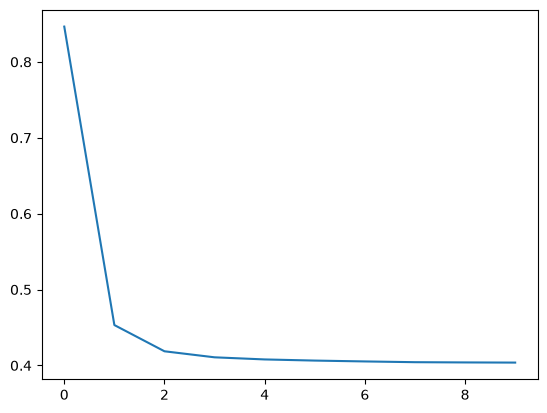

In [9]:
plt.plot(history.history["loss"])
plt.show()

## Reconstruction Error as a Fraud Score
- Slides 7-8

In [10]:
X_back = model.predict(X_train, verbose=0)
errors = ((X_train - X_back) ** 2).sum(axis=1)
errors.groupby(y_train).mean()

Class
0     11.192344
1    305.051248
dtype: float64

In [11]:
average_precision_score(y_train, errors)

0.2461759033120552

## One Function for Every Autoencoder
- Slide 9
- The rest of the section only changes the layers between input and output

In [12]:
def train_autoencoder(layers, inputs=X_train, epochs=10):
    model = keras.Sequential([keras.Input(shape=(29,)), *layers, keras.layers.Dense(29)])
    model.compile(optimizer="adam", loss="mse")
    model.fit(inputs, X_train, epochs=epochs, batch_size=256, verbose=0)
    errors = ((X_train - model.predict(X_train, verbose=0)) ** 2).sum(axis=1)
    return model, average_precision_score(y_train, errors)

- Train the same model again: the score moves from run to run

In [13]:
results = {}
_, results["linear 10"] = train_autoencoder([keras.layers.Dense(10)])
results["linear 10"]

0.2453945367537735

## A Bottleneck as Wide as the Input
- Slide 10
- 29 units for 29 features: nothing has to be thrown away

In [14]:
_, results["linear 29"] = train_autoencoder([keras.layers.Dense(29)])
results["linear 29"]

0.4135992363671125

- The same model, trained five times longer

In [15]:
_, results["linear 29, 50 epochs"] = train_autoencoder([keras.layers.Dense(29)],
                                                       epochs=50)
results["linear 29, 50 epochs"]

0.05048320245790304

## Nonlinear Activations
- Slide 11

In [16]:
_, results["relu 10"] = train_autoencoder([keras.layers.Dense(10, activation="relu")])
results["relu 10"]

0.3114510229609739

## More Layers
- 29 → 20 → 10 → 20 → 29

In [17]:
_, results["tanh 20-10-20"] = train_autoencoder([
    keras.layers.Dense(20, activation="tanh"),
    keras.layers.Dense(10, activation="tanh"),
    keras.layers.Dense(20, activation="tanh"),
])
results["tanh 20-10-20"]

0.1529959530237651

## Overcomplete Autoencoders
- Slide 12
- 40 units: more room than the input needs

In [18]:
_, results["linear 40"] = train_autoencoder([keras.layers.Dense(40)])
results["linear 40"]

0.6537527634748274

- Dropout switches off 10% of the units at random on every batch

In [19]:
_, results["linear 40, dropout"] = train_autoencoder([keras.layers.Dense(40),
                                                      keras.layers.Dropout(0.1)])
results["linear 40, dropout"]

0.13501968659243418

- Sparse: an L1 penalty on the 40 units keeps most of them near zero

In [20]:
_, results["linear 40, L1"] = train_autoencoder([
    keras.layers.Dense(40, activity_regularizer=keras.regularizers.l1(1e-4)),
])
results["linear 40, L1"]

0.5575218769444905

## Denoising Autoencoder
- Slide 13
- Input: transactions with random noise added; target: the clean transactions

In [21]:
X_noisy = X_train + np.random.normal(0, 0.5, X_train.shape)
_, results["denoising 10"] = train_autoencoder([keras.layers.Dense(10)], inputs=X_noisy)
results["denoising 10"]

0.24306974145899857

## Comparing the Autoencoders
- Rerun the section: the wide models swing the most from run to run

In [22]:
pd.Series(results).sort_values()

linear 29, 50 epochs    0.050483
linear 40, dropout      0.135020
tanh 20-10-20           0.152996
denoising 10            0.243070
linear 10               0.245395
relu 10                 0.311451
linear 29               0.413599
linear 40, L1           0.557522
linear 40               0.653753
dtype: float64

## Checking on the Test Set
- The first linear autoencoder against PCA, both fitted on the training data only

In [23]:
test_errors = ((X_test - model.predict(X_test, verbose=0)) ** 2).sum(axis=1)
pca_test_errors = ((X_test - pca.inverse_transform(pca.transform(X_test)))
                   ** 2).sum(axis=1)
(average_precision_score(y_test, test_errors),
 average_precision_score(y_test, pca_test_errors))

(0.26564308042218715, 0.27078729711383587)

## Part 2: Semi-Supervised Learning
- Slide 14
- Pretend only 2% of the training rows were ever checked by an analyst

In [24]:
X_few, _, y_few, _ = train_test_split(X_train, y_train, train_size=0.02,
                                      stratify=y_train)
len(y_few), y_few.sum()

(3816, np.int64(7))

## Supervised on the Few Labels

In [25]:
few = LogisticRegression(max_iter=1000).fit(X_few, y_few)
semi = {"autoencoder only": average_precision_score(y_test, test_errors)}
semi["few labels"] = average_precision_score(y_test, few.predict_proba(X_test)[:, 1])
semi["few labels"]

0.5189888827442065

## Few Labels Plus the Autoencoder's Error
- Slide 15
- The reconstruction error becomes one extra feature

In [26]:
few_errors = ((X_few - model.predict(X_few, verbose=0)) ** 2).sum(axis=1)
both = LogisticRegression(max_iter=1000).fit(X_few.assign(error=few_errors), y_few)
semi["few labels + error"] = average_precision_score(
    y_test, both.predict_proba(X_test.assign(error=test_errors))[:, 1])
semi["few labels + error"]

0.6198369911845176

## Self-Training
- Slide 16
- Unlabelled rows get the label -1
- The model labels the rows it is surest about, retrains, and repeats

In [27]:
y_semi = y_train.where(y_train.index.isin(y_few.index), -1)
y_semi.value_counts()

Class
-1    187004
 0      3809
 1         7
Name: count, dtype: int64

In [28]:
self_training = SelfTrainingClassifier(
    LogisticRegression(max_iter=1000)).fit(X_train, y_semi)
semi["self-training"] = average_precision_score(
    y_test, self_training.predict_proba(X_test)[:, 1])
semi["self-training"]

0.46687961740679756

- How many rounds it ran, and how many rows it labelled fraud

In [29]:
self_training.n_iter_, (self_training.transduction_ == 1).sum()

(4, np.int64(153))

## Every Label, for Reference
- Slide 17

In [30]:
full = LogisticRegression(max_iter=1000).fit(X_train, y_train)
semi["all labels"] = average_precision_score(y_test, full.predict_proba(X_test)[:, 1])
pd.Series(semi).sort_values()

autoencoder only      0.265643
self-training         0.466880
few labels            0.518989
few labels + error    0.619837
all labels            0.787205
dtype: float64

## Lab: More or Fewer Labels
- Change `train_size` to 0.005 and to 0.1, and rerun the few-label cells
- Does the autoencoder's error help more when labels are scarcer?

## Wrap-Up
- Slides 18-20